# Tuned SBO Convergence Evaluation: Pure Deterministic vs. Spatial Proxy (N_init=50, K=10)
Notebook ini menjalankan ulang simulasi *Surrogate-Based Optimization* (SBO) menggunakan dataset riil `data_kecepatan.csv`. Eksperimen ini menetapkan $N_{init} = 50$ dan $K = 10$ evaluasi sekuensial.

**Perbaikan pada versi ini (Optimized Proxy):**
1.  **Normalisasi Jarak:** Jarak minimum (`d_min`) dinormalisasi ke skala 0-1 untuk menstabilkan perhitungan ketidakpastian.
2.  **Penguatan Eksplorasi (Exploration Factor):** Faktor kalibrasi proksi ditingkatkan agar algoritma lebih aktif memeriksa area kosong.
3.  **Tuning EI Xi:** Nilai `xi` pada *Expected Improvement* diseimbangkan (0.05) agar model mengeksplorasi secara memadai namun tidak kehilangan fokus pada area dengan prediksi nilai optimal yang tinggi.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from scipy.stats import norm
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Load Dataset
try:
    df = pd.read_csv('data_kecepatan.csv', sep=';').dropna()
    print(f"Dataset dimuat: {df.shape[0]} observasi.")
except FileNotFoundError:
    print("Error: File 'data_kecepatan.csv' tidak ditemukan. Pastikan file ada di direktori eksekusi.")
    # Fallback dummy data jika dijalankan tanpa CSV
    np.random.seed(42)
    dummy_data = np.random.rand(1000, 5) * np.array([89, 89, 1, 1, 1])
    dummy_target = np.random.rand(1000) * 10
    df = pd.DataFrame(np.c_[dummy_data, dummy_target], columns=['A2', 'A3', 'L2', 'L3', 'Throat', 'Max_v'])

features = ['A2', 'A3', 'L2', 'L3', 'Throat']
X = df[features].values
y = df['Max_v'].values

# True global optimum
true_optimum_idx = np.argmax(y)
true_optimum_val = y[true_optimum_idx]
print(f"True Global Optimum (Dataset Max): {true_optimum_val:.4f}")


Dataset dimuat: 1000 observasi.
True Global Optimum (Dataset Max): 9.7256


## Algoritma SBO dengan Tuned Spatial Distance Proxy


In [3]:
def run_sbo(X_all, y_all, model_name, use_proxy, n_init, n_iter, random_state):
    np.random.seed(random_state)

    # 1. Normalisasi Ruang Desain
    scaler_X = MinMaxScaler()
    X_scaled = scaler_X.fit_transform(X_all)
    d = X_scaled.shape[1]

    # 2. Latin Hypercube Sampling Approximation (Random Subsampling)
    indices = np.arange(len(X_all))
    np.random.shuffle(indices)

    train_idx = indices[:n_init]
    pool_idx = indices[n_init:]

    X_train = X_scaled[train_idx]
    y_train = y_all[train_idx]

    X_pool = X_scaled[pool_idx]
    y_pool_true = y_all[pool_idx]

    best_y_history = [np.max(y_train)]

    # Inisialisasi Model Deterministik (Tuned)
    if model_name == 'SVR':
        model = SVR(C=50, gamma='scale', kernel='rbf')
    elif model_name == 'MLP':
        model = MLPRegressor(hidden_layer_sizes=(100, 50), random_state=random_state, max_iter=1000, early_stopping=True)
    elif model_name == 'GBR':
        model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, random_state=random_state)
    else:
        raise ValueError("Unknown model")

    # 3. Iterative Active Learning (Sequential K=10)
    for t in range(n_iter):
        model.fit(X_train, y_train)
        mu_pred = model.predict(X_pool)
        f_best = np.max(y_train)

        if use_proxy:
            # Spatial Uncertainty Proxy Teroptimasi
            distances = cdist(X_pool, X_train, metric='euclidean')
            d_min = np.min(distances, axis=1)

            # Min-Max Normalization pada d_min agar skalanya stabil (0 - 1)
            d_min_norm = (d_min - np.min(d_min)) / (np.max(d_min) - np.min(d_min) + 1e-9)

            sigma_y = np.std(y_train)

            # Penguat Eksplorasi: Ditingkatkan agar proxy memberikan dorongan kuat pada area kosong
            exploration_factor = 3.5
            sigma_proxy = (d_min_norm * sigma_y * exploration_factor)
            sigma_proxy = np.maximum(sigma_proxy, 1e-9) # Hindari division by zero

            # Expected Improvement (EI) dengan Xi seimbang (0.05)
            xi = 0.05 # Dikurangi sedikit dari 0.1 agar tidak kehilangan area eksploitasi yang sudah bagus
            Z = (mu_pred - f_best - xi) / sigma_proxy
            ei = (mu_pred - f_best - xi) * norm.cdf(Z) + sigma_proxy * norm.pdf(Z)

            next_idx_in_pool = np.argmax(ei)
        else:
            # Pure Exploitation (One-Shot Equivalent but sequential)
            next_idx_in_pool = np.argmax(mu_pred)

        # Evaluasi Aktual
        x_next = X_pool[next_idx_in_pool].reshape(1, -1)
        y_next = y_pool_true[next_idx_in_pool]

        # Update set data
        X_train = np.vstack([X_train, x_next])
        y_train = np.append(y_train, y_next)

        # Hapus kandidat terpilih dari pool
        X_pool = np.delete(X_pool, next_idx_in_pool, axis=0)
        y_pool_true = np.delete(y_pool_true, next_idx_in_pool)

        best_y_history.append(np.max(y_train))

    return best_y_history


## Menjalankan Eksperimen ($N_{init}=50$, $K=10$)
Mensimulasikan anggaran komputasi spesifik sesuai metodologi pada naskah (50 sampel DoE awal + 10 evaluasi tambahan).


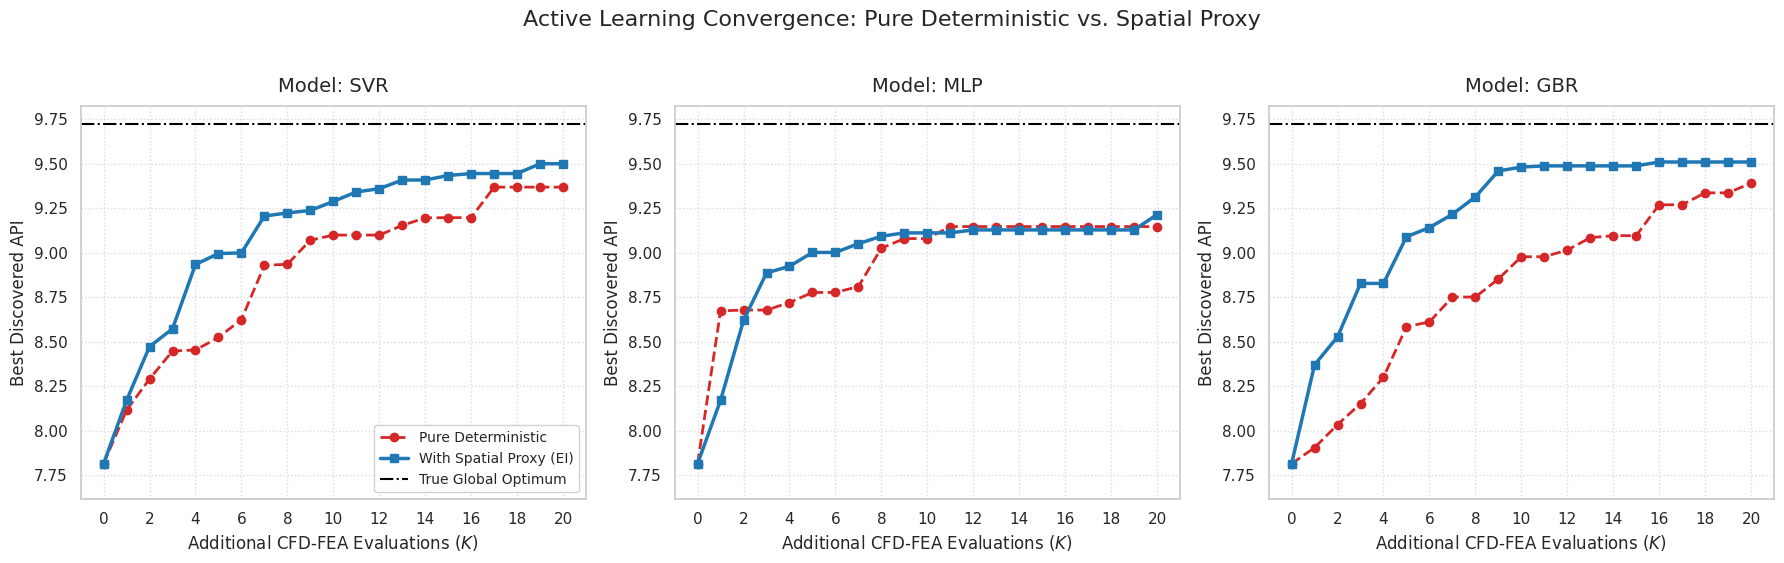

In [17]:
models = ['SVR', 'MLP', 'GBR']
n_init = 5
n_iter = 20
runs = 10

results = {}

for model in models:
    results[model] = {'pure': np.zeros(n_iter + 1), 'proxy': np.zeros(n_iter + 1)}

    for i in range(runs):
        seed = 100 + i

        # Pure Deterministic
        hist_pure = run_sbo(X, y, model, use_proxy=False, n_init=n_init, n_iter=n_iter, random_state=seed)
        results[model]['pure'] += np.array(hist_pure)

        # Deterministic with Spatial Proxy
        hist_proxy = run_sbo(X, y, model, use_proxy=True, n_init=n_init, n_iter=n_iter, random_state=seed)
        results[model]['proxy'] += np.array(hist_proxy)

    # Average results
    results[model]['pure'] /= runs
    results[model]['proxy'] /= runs

# Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle(f"Active Learning Convergence: Pure Deterministic vs. Spatial Proxy", fontsize=16, y=1.02)

x_axis = np.arange(n_iter + 1)

for idx, model in enumerate(models):
    ax = axes[idx]

    ax.plot(x_axis, results[model]['pure'], marker='o', markersize=6, linestyle='--', color='#d62728', linewidth=2, label='Pure Deterministic')
    ax.plot(x_axis, results[model]['proxy'], marker='s', markersize=6, linestyle='-', color='#1f77b4', linewidth=2.5, label='With Spatial Proxy (EI)')
    ax.axhline(true_optimum_val, color='black', linestyle='-.', linewidth=1.5, label='True Global Optimum')

    ax.set_title(f"Model: {model}", fontsize=14, pad=10)
    ax.set_xlabel("Additional CFD-FEA Evaluations ($K$)", fontsize=12)
    ax.set_ylabel("Best Discovered API", fontsize=12)
    ax.set_xticks(np.arange(0, n_iter + 1, 2))
    ax.grid(True, linestyle=':', alpha=0.7)

    min_y = min(np.min(results[model]['pure']), np.min(results[model]['proxy']))
    ax.set_ylim([min_y - 0.2, true_optimum_val + 0.1])

    if idx == 0:
        ax.legend(loc='lower right', frameon=True, framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()
